# Oscillations and waves 1: The harmonic oscillator

*Learning path: oscillations and waves, part 1 of 7.* [Index](README.md) · Next: [Coupled oscillators](02-coupled-oscillators.ipynb)

A singer holds a note, and a wine glass across the room shatters. A car drives over a speed bump and bobs once, not
ten times. A clock pendulum keeps time for a week on one winding. All three are the same system: a mass, a restoring
force proportional to the displacement, and some friction. It is the most important model in physics, because almost
anything near a stable equilibrium behaves like it: atoms in a crystal, the air in a flute, the current in a radio
circuit. This lesson solves it completely, with friction and with a driving force, and explains resonance.

**Who this is for.** You know derivatives and have seen differential equations ([foundations
8](../foundations/README.md)); [mechanics 1](../mechanics/01-motion-and-newtons-laws.ipynb) helps.

**What you will be able to do afterwards:**

1. solve the free oscillator and compute its frequency from the mass and spring;
2. tell underdamped, critically damped and overdamped motion apart, and design for critical damping;
3. compute the response to a periodic force and the resonance curve;
4. use the quality factor $Q$ to describe how sharp a resonance is and how long ringing lasts.

Plan about an hour and a half.

## 1. The free oscillator

A mass $m$ on a spring of stiffness $k$ obeys $m\ddot x = -kx$, or $\ddot x + \omega_0^2x = 0$ with
$\omega_0 = \sqrt{k/m}$. Pulled to $x = A$ and let go:

In [1]:
dsolve(x'' + w^2*x == 0, x, t, 0, [A, 0])

A*cos(t*w)

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

A cosine with **angular frequency** $\omega_0$: it repeats every $T = 2\pi/\omega_0$, that is $f = \omega_0/2\pi$
times per second, whatever the amplitude $A$. (That independence is why pendulum clocks work.) A 0.5 kg mass on a
spring of 2000 N/m:

In [2]:
k = 2000 N/m;
m = 0.5 kg;
eval(convert(sqrt(k/m)/(2*pi), Hz), 4)

10.07 Hz

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Four times the mass halves the frequency; four times the stiffness doubles it. The energy
$\tfrac12m\dot x^2 + \tfrac12kx^2$ passes back and forth between the mass and the spring and stays constant (as in
[mechanics 2](../mechanics/02-energy-and-momentum.ipynb)).

**Try this.** A guitar string's frequency also goes like the square root of a stiffness (the tension). By what factor
must the tension rise to raise the note by an octave (twice the frequency)?

## 2. Damping

Add friction proportional to the velocity, $-c\dot x$. Dividing by $m$: $\ddot x + \gamma\dot x + \omega_0^2x = 0$
with $\gamma = c/m$. Trying $x = e^{st}$ gives $s^2 + \gamma s + \omega_0^2 = 0$, and the answer depends on whether
the roots are complex. With $\omega_0^2 = 9$ and three amounts of friction:

In [3]:
dsolve(x'' + 2*x' + 9*x == 0, x, t, 0, [1, 0])
dsolve(x'' + 6*x' + 9*x == 0, x, t, 0, [1, 0])
dsolve(x'' + 10*x' + 9*x == 0, x, t, 0, [1, 0])

exp(-t)*sin(2*sqrt(2)*t)/(2*sqrt(2))+exp(-t)*cos(2*sqrt(2)*t)

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

exp(-3*t)*(3*t+1)

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

9*exp(-t)/8-exp(-9*t)/8

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

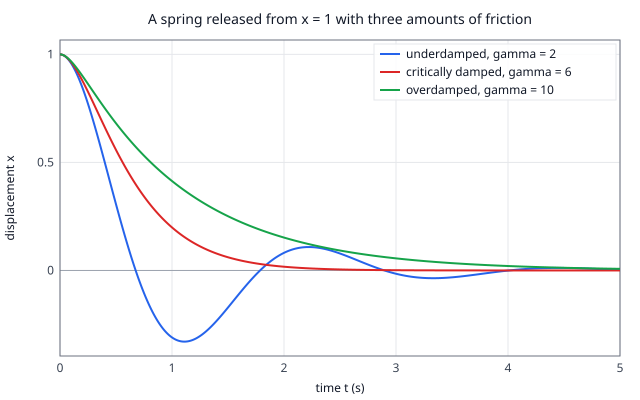

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
p = plot(exp(-t)*(cos(2*sqrt(2)*t) + sin(2*sqrt(2)*t)/(2*sqrt(2))), t, 0, 5);
p = show(p, plot(exp(-3*t)*(3*t + 1), t, 0, 5));
p = show(p, plot(9*exp(-t)/8 - exp(-9*t)/8, t, 0, 5));
p = legend(p, "underdamped, gamma = 2", "critically damped, gamma = 6", "overdamped, gamma = 10");
labels(title(p, "A spring released from x = 1 with three amounts of friction"), "time t (s)", "displacement x")

* **Underdamped** ($\gamma < 2\omega_0$): it still oscillates, inside an envelope $e^{-\gamma t/2}$, slightly slower
  than without friction.
* **Critically damped** ($\gamma = 2\omega_0$): it returns to rest as fast as possible without overshooting.
* **Overdamped** ($\gamma > 2\omega_0$): it creeps back, slowed by too much friction.

Car suspensions and door closers are designed near critical damping. For a quarter of a 1200 kg car (300 kg) on a
spring of 30 000 N/m, the shock absorber should have $c = 2\sqrt{km}$:

In [5]:
m = 300 kg;
k = 30000 N/m;
convert(2*sqrt(k*m), N*s/m)

6000 N*s/m

> `convert`: Converts a quantity to other units of the same dimension: convert(100 km/h, m/s), convert(2 kg*3 m/s^2, N).

**Try this.** Worn shock absorbers have a third of that. How many times does the car bounce (roughly) before
settling? Solve with $\omega_0^2 = 100$ and $\gamma = 20/3$.

## 3. Driven oscillations and resonance

Now push periodically: $\ddot x + \gamma\dot x + \omega_0^2x = \cos\omega t$. Start at rest with $\omega_0 = 1$,
light damping $\gamma = 0.2$, and push exactly at the natural frequency:

In [6]:
dsolve(x'' + 0.2*x' + x == cos(t), x, t, 0, [0, 0])

5.0*sin(t)-5.02518907629606*exp(-0.1*t)*sin(0.99498743710662*t)

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

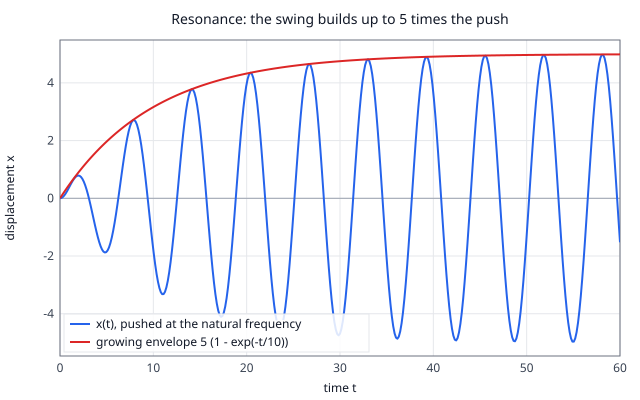

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
p = plot(5*sin(t) - 5.025*exp(-0.1*t)*sin(0.995*t), t, 0, 60);
p = show(p, plot(5*(1 - exp(-0.1*t)), t, 0, 60));
p = legend(p, "x(t), pushed at the natural frequency", "growing envelope 5 (1 - exp(-t/10))");
labels(title(p, "Resonance: the swing builds up to 5 times the push"), "time t", "displacement x")

The swing grows until friction removes energy as fast as the push supplies it. Then a **steady state** remains,
oscillating at the driving frequency. Its amplitude, for any driving frequency, is

$$A(\omega) = \frac{1}{\sqrt{(\omega_0^2 - \omega^2)^2 + \gamma^2\omega^2}}.$$

Measure the friction by the **quality factor** $Q = \omega_0/\gamma$. With $\omega_0 = 1$:

In [8]:
assume(Q > 0);
A(w, Q) := 1/sqrt((1 - w^2)^2 + (w/Q)^2);
simplify(A(1, Q))

Q

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

At resonance the response is $Q$ times the response to a steady push. The resonance curves:

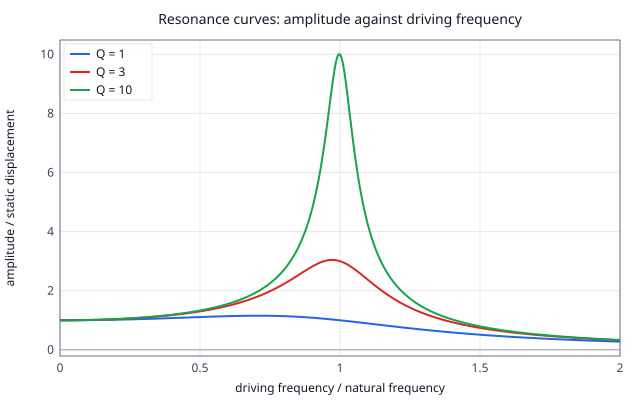

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
p = plot(A(w, 1), w, 0, 2);
p = show(p, plot(A(w, 3), w, 0, 2));
p = show(p, plot(A(w, 10), w, 0, 2));
p = legend(p, "Q = 1", "Q = 3", "Q = 10");
labels(title(p, "Resonance curves: amplitude against driving frequency"), "driving frequency / natural frequency", "amplitude / static displacement")

The higher $Q$, the taller and narrower the peak. Its width (where the energy falls to half its peak) is
$\Delta\omega \approx \omega_0/Q$. Far above resonance the mass can't keep up, and moves opposite to the force.

**Try this.** For $Q = 10$, compute `A(1.05, 10)`. How much does a 5% miss in frequency cost?

## 4. The quality factor

$Q$ has a second meaning: the energy of a free oscillator decays like $e^{-\gamma t}$, so in one cycle of length
$2\pi/\omega_0$ it loses the fraction $1 - e^{-2\pi/Q} \approx 2\pi/Q$. A high-$Q$ system rings for about $Q/\pi$
cycles before its energy falls by a factor $e^2$.

| oscillator | $Q$ (roughly) |
|---|---|
| car suspension | 0.5 |
| guitar string | 1 000 |
| wine glass | 1 000 |
| quartz watch crystal | 10 000 to 100 000 |
| best superconducting microwave cavities | $10^{10}$ |

A wine glass with $Q \approx 1000$ will, when sung to at exactly its frequency, build up to a thousand times the
motion that the same sound pressure would cause off resonance. That is what breaks it, and why the singer must hit the
pitch within a tenth of a percent. A quartz crystal's huge $Q$ makes its frequency (32 768 Hz in a watch) so sharp
that the watch drifts by less than a second a day.

**Try this.** A tuning fork at 440 Hz rings for about 10 s before its sound dies away. Estimate its $Q$.

## Summary

* $\ddot x + \omega_0^2x = 0$ gives oscillation at $\omega_0 = \sqrt{k/m}$, whatever the amplitude.
* Damping $\gamma$: underdamped below $2\omega_0$, critical at $2\omega_0$ (fastest return), overdamped above.
* A periodic push gives a steady state with amplitude $1/\sqrt{(\omega_0^2 - \omega^2)^2 + \gamma^2\omega^2}$: a
  resonance peak at $\omega_0$, $Q$ times the static response, with width $\omega_0/Q$.
* $Q = \omega_0/\gamma$ also counts how many cycles a free oscillation rings.

Next: [coupled oscillators](02-coupled-oscillators.ipynb), where several oscillators share their energy.

## Exercises

1. **Pendulum.** For small swings, a pendulum of length $\ell$ is an oscillator with $\omega_0^2 = g/\ell$. How long
   must a pendulum be to tick once a second (period 2 s)?
2. **Bungee.** A 70 kg jumper on a cord with $k = 200$ N/m: what is the period of the bounce?
3. **Critical damping.** Show from $s^2 + \gamma s + \omega_0^2 = 0$ that the motion stops oscillating at
   $\gamma = 2\omega_0$.
4. **Peak position.** Show that the amplitude peaks at $\omega = \sqrt{\omega_0^2 - \gamma^2/2}$, slightly below
   $\omega_0$. (Differentiate the expression under the square root.)
5. **Phase.** The steady state lags the force by the angle $\delta$ with $\tan\delta = \gamma\omega/(\omega_0^2 -
   \omega^2)$. Plot $\delta$ for $Q = 3$. What is it at resonance?
6. **LC circuit.** A coil $L$ and capacitor $C$ obey $L\ddot q + q/C = 0$. What plays the role of the mass and of the
   spring? Find the frequency for $L = 1$ mH, $C = 1$ nF.

## Hints and answers

* **Section 1, Try this.** Four times the tension.
* **Section 2, Try this.** `dsolve(x'' + 20/3*x' + 100*x == 0, x, t, 0, [1, 0])`: oscillation at
  $\sqrt{100 - 100/9} \approx 9.4$ per second inside $e^{-10t/3}$; the envelope falls to 5% in about 0.9 s, about
  one and a half bounces.
* **Section 3, Try this.** 6.8 against 10 at resonance: a third of the response lost.
* **Section 4, Try this.** The energy decays like $e^{-\gamma t}$; taking "dies away" as a factor $e^{-5}$ in 10 s,
  $\gamma = 0.5$ per second and $Q = 2\pi \cdot 440/0.5 \approx 5500$.
* **Exercise 1.** $\ell = g/\pi^2 \approx 0.994$ m.
* **Exercise 2.** $2\pi\sqrt{70/200} \approx 3.7$ s.
* **Exercise 3.** The roots are $(-\gamma \pm \sqrt{\gamma^2 - 4\omega_0^2})/2$: real exactly when
  $\gamma \ge 2\omega_0$.
* **Exercise 4.** $\frac{d}{d\omega}[(\omega_0^2 - \omega^2)^2 + \gamma^2\omega^2] = 0$ gives
  $\omega^2 = \omega_0^2 - \gamma^2/2$.
* **Exercise 5.** 90° at resonance, rising from 0 well below to 180° well above.
* **Exercise 6.** $L$ is the mass, $1/C$ the stiffness: $f = 1/(2\pi\sqrt{LC}) \approx 159$ kHz.

## Sources

1. A. P. French, *Vibrations and Waves*, Norton (1971), chapters 3 and 4.
2. H. Georgi, *The Physics of Waves*, Prentice Hall (1993), chapters 1 and 2.
3. W. Marrison, "The evolution of the quartz crystal clock", *Bell System Technical Journal* 27, 510–588 (1948).